In [1]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, KMeans
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

path = kagglehub.dataset_download("helmynaufal/country-data")
print("Path to dataset files: ", path)

csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, csv_file))
df.head()

Using Colab cache for faster access to the 'country-data' dataset.
Path to dataset files:  /kaggle/input/country-data


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [2]:
features = df.drop(columns=['country'])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

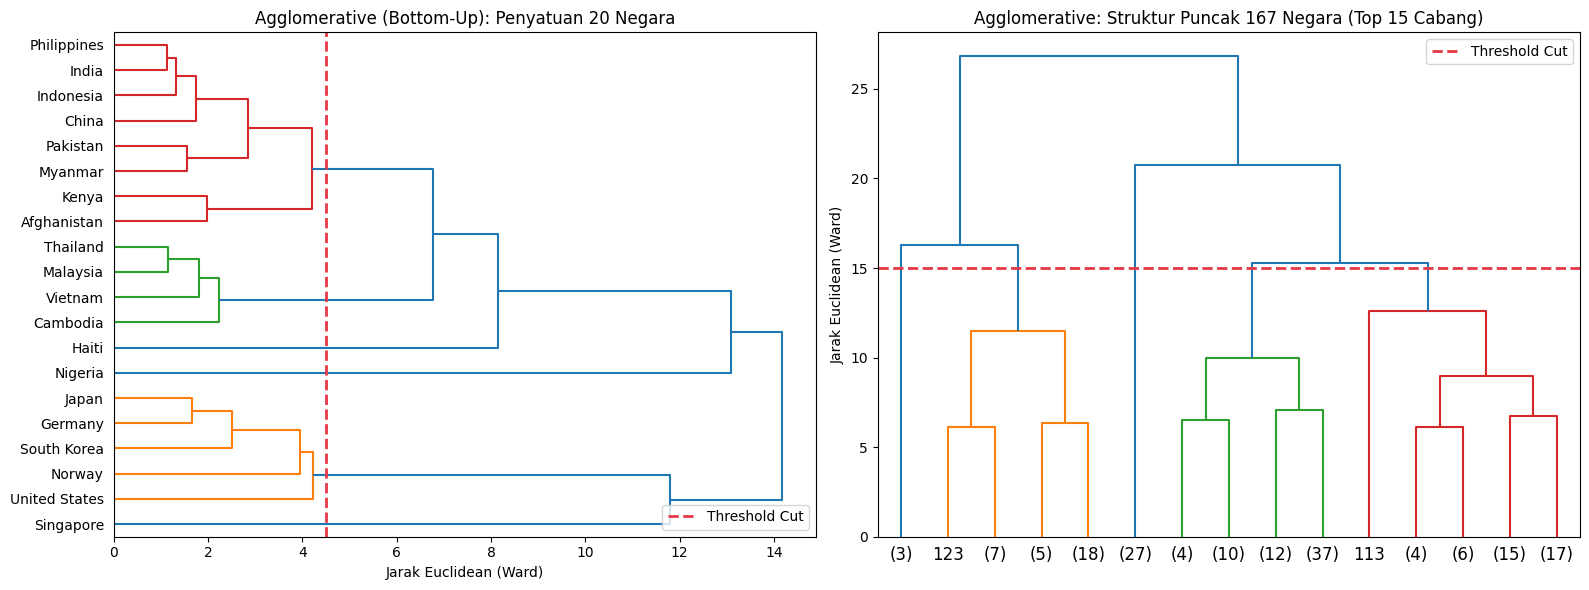

In [4]:
selected_countries = [
    'Indonesia', 'Philippines', 'Vietnam', 'Thailand', 'Malaysia',
    'China', 'India', 'Cambodia', 'Myanmar', 'Singapore',
    'Japan', 'South Korea', 'United States', 'Germany', 'Norway',
    'Nigeria', 'Haiti', 'Afghanistan', 'Kenya', 'Pakistan'
]

df_sub = df[df['country'].isin(selected_countries)].reset_index(drop=True)
X_sub = scaler.transform(df_sub.drop(columns=['country']))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

Z_sub = linkage(X_sub, method='ward')
dendrogram(Z_sub, labels=df_sub['country'].values, orientation='right', color_threshold=4.5, ax=axes[0], leaf_font_size=10)
axes[0].axvline(x=4.5, color='#E63946', linestyle='--', linewidth=2, label='Threshold Cut')
axes[0].set_title('Agglomerative (Bottom-Up): Penyatuan 20 Negara')
axes[0].set_xlabel('Jarak Euclidean (Ward)')
axes[0].legend(loc='lower right')

Z_full = linkage(X_scaled, method='ward')
dendrogram(Z_full, truncate_mode='lastp', p=15, color_threshold=15.0, ax=axes[1], show_leaf_counts=True)
axes[1].axhline(y=15.0, color='#E63946', linestyle='--', linewidth=2, label='Threshold Cut')
axes[1].set_title('Agglomerative: Struktur Puncak 167 Negara (Top 15 Cabang)')
axes[1].set_ylabel('Jarak Euclidean (Ward)')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

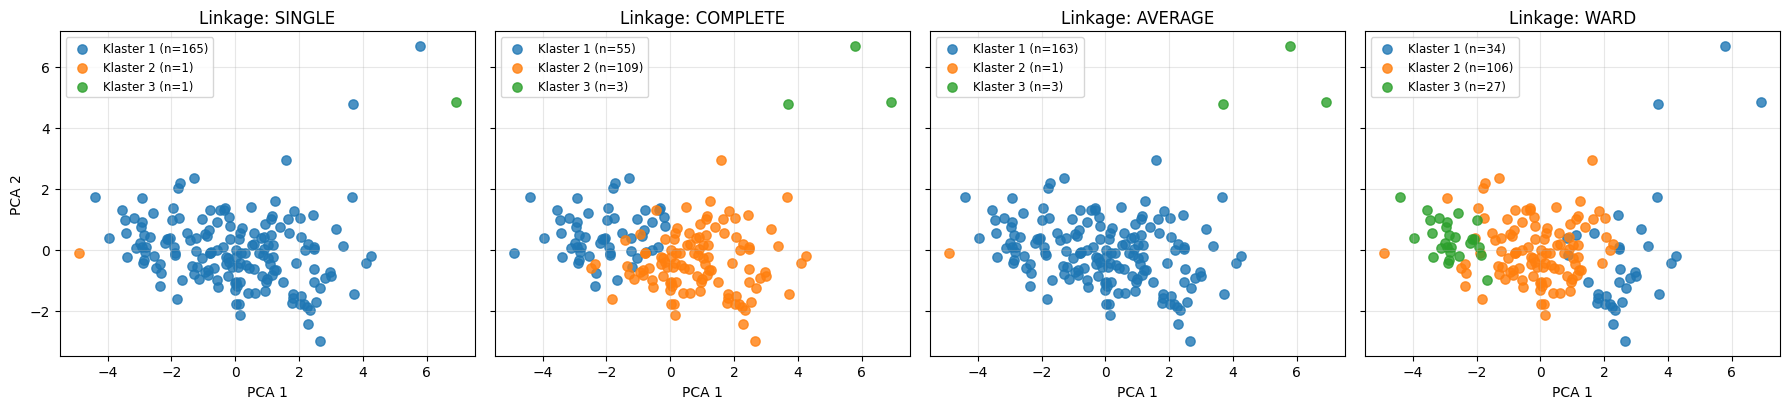

In [5]:
linkage_methods = ['single', 'complete', 'average', 'ward']
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)

for idx, method in enumerate(linkage_methods):
    model = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels = model.fit_predict(X_scaled)
    counts = np.bincount(labels)

    for c in range(3):
        mask = labels == c
        axes[idx].scatter(X_pca[mask, 0], X_pca[mask, 1], label=f'Klaster {c+1} (n={counts[c]})', alpha=0.8, s=45)

    axes[idx].set_title(f'Linkage: {method.upper()}')
    axes[idx].set_xlabel('PCA 1')
    if idx == 0:
        axes[idx].set_ylabel('PCA 2')
    axes[idx].legend(loc='upper left', fontsize=8.5)
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


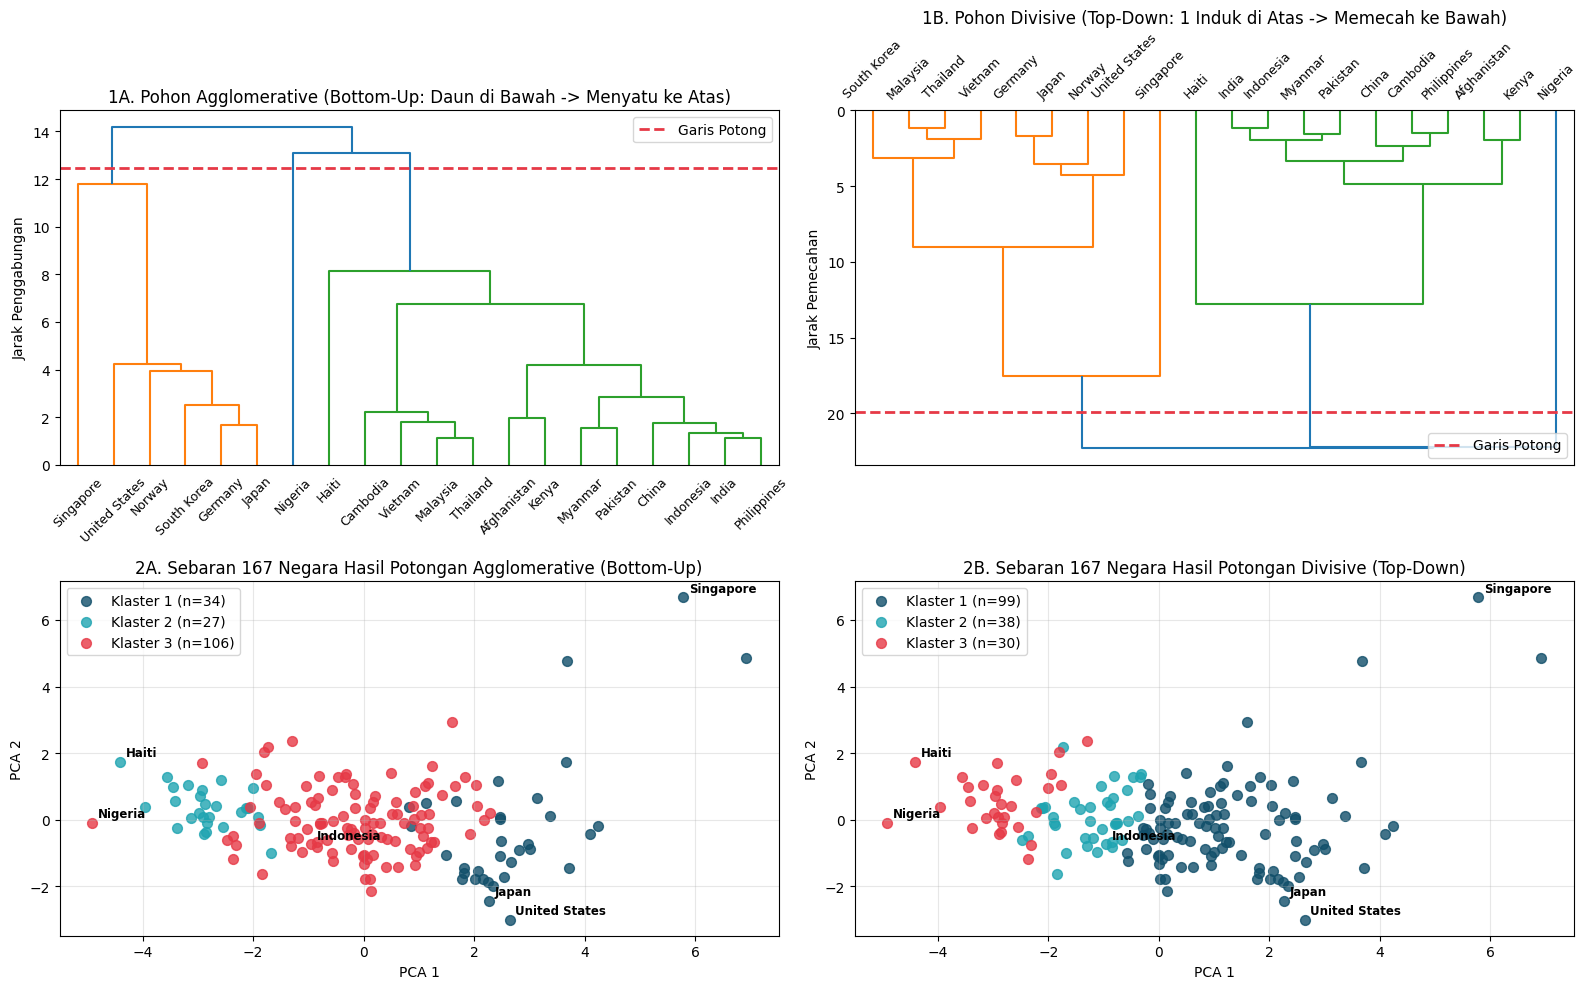

In [6]:
def build_divisive_tree(X):
    n = len(X)
    internal_nodes = []

    def split_recursive(indices):
        if len(indices) == 1:
            return {'id': indices[0], 'height': 0.0, 'count': 1}
        if len(indices) == 2:
            left = split_recursive([indices[0]])
            right = split_recursive([indices[1]])
            h = float(np.linalg.norm(X[indices[0]] - X[indices[1]]))
        else:
            km = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X[indices])
            idx0 = [indices[i] for i in range(len(indices)) if km.labels_[i] == 0]
            idx1 = [indices[i] for i in range(len(indices)) if km.labels_[i] == 1]
            left = split_recursive(idx0)
            right = split_recursive(idx1)
            h = float(np.linalg.norm(km.cluster_centers_[0] - km.cluster_centers_[1]) * np.sqrt(len(indices) / 2))

        h = max(h, left['height'] + 0.05, right['height'] + 0.05)
        node = {'left': left, 'right': right, 'height': h, 'count': len(indices)}
        internal_nodes.append(node)
        return node

    split_recursive(list(range(n)))
    internal_nodes.sort(key=lambda x: x['height'])

    Z = np.zeros((n - 1, 4))
    for i, node in enumerate(internal_nodes):
        node['id'] = n + i
        Z[i] = [node['left']['id'], node['right']['id'], node['height'], node['count']]
    return Z

Z_agg_sub = linkage(X_sub, method='ward')
Z_div_sub = build_divisive_tree(X_sub)

Z_agg_full = linkage(X_scaled, method='ward')
Z_div_full = build_divisive_tree(X_scaled)

labels_agg = fcluster(Z_agg_full, t=3, criterion='maxclust')
labels_div = fcluster(Z_div_full, t=3, criterion='maxclust')

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

cut_agg = (Z_agg_sub[-2, 2] + Z_agg_sub[-3, 2]) / 2
dendrogram(Z_agg_sub, labels=df_sub['country'].values, color_threshold=cut_agg, ax=axes[0, 0], leaf_rotation=45, leaf_font_size=9)
axes[0, 0].axhline(y=cut_agg, color='#E63946', linestyle='--', linewidth=2, label='Garis Potong')
axes[0, 0].set_title('1A. Pohon Agglomerative (Bottom-Up: Daun di Bawah -> Menyatu ke Atas)')
axes[0, 0].set_ylabel('Jarak Penggabungan')
axes[0, 0].legend(loc='upper right')

cut_div = (Z_div_sub[-2, 2] + Z_div_sub[-3, 2]) / 2
dendrogram(Z_div_sub, labels=df_sub['country'].values, color_threshold=cut_div, orientation='bottom', ax=axes[0, 1], leaf_rotation=45, leaf_font_size=9)
axes[0, 1].axhline(y=cut_div, color='#E63946', linestyle='--', linewidth=2, label='Garis Potong')
axes[0, 1].set_title('1B. Pohon Divisive (Top-Down: 1 Induk di Atas -> Memecah ke Bawah)')
axes[0, 1].set_ylabel('Jarak Pemecahan')
axes[0, 1].legend(loc='lower right')

palette = ['#114F6A', '#1FA4B1', '#E63946']
highlight = ['Indonesia', 'Singapore', 'Nigeria', 'Japan', 'Haiti', 'United States']

for c in [1, 2, 3]:
    mask_a = labels_agg == c
    axes[1, 0].scatter(X_pca[mask_a, 0], X_pca[mask_a, 1], label=f'Klaster {c} (n={mask_a.sum()})', color=palette[c-1], alpha=0.8, s=50)

    mask_d = labels_div == c
    axes[1, 1].scatter(X_pca[mask_d, 0], X_pca[mask_d, 1], label=f'Klaster {c} (n={mask_d.sum()})', color=palette[c-1], alpha=0.8, s=50)

for ax, title in zip([axes[1, 0], axes[1, 1]], [
    '2A. Sebaran 167 Negara Hasil Potongan Agglomerative (Bottom-Up)',
    '2B. Sebaran 167 Negara Hasil Potongan Divisive (Top-Down)'
]):
    for name in highlight:
        idx_c = df[df['country'] == name].index[0]
        ax.annotate(name, (X_pca[idx_c, 0], X_pca[idx_c, 1]), fontsize=8.5, fontweight='bold', xytext=(4, 4), textcoords='offset points')
    ax.set_title(title)
    ax.set_xlabel('PCA 1')
    ax.set_ylabel('PCA 2')
    ax.legend(loc='upper left')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()